# Fase 6 — Implantação

**Projeto:** Supply Chain Forecasting — Rede Bandeirante · **Produto foco:** P0131

## Objetivo
Transformar a previsão em uma **política de pedido explicável** para a tela do comprador, no
ritual de quinta-feira. A decisão não é "o número", e sim a conta aberta que o produz:

```
pedido = demanda prevista + estoque de segurança - estoque disponível no CD
```

## Cenário
- **Previsão:** SARIMAX (2,1,2)(1,1,1,7), `trend='ct'`, com a exógena `pct_lojas_promo`
  do período de teste (holdout de 28 dias da Fase 4).
- **Estoque de segurança:** quantil 93,75% dos erros do SARIMAX no backtest de 12 origens
  (Fase 5) → ≈ **783,6 un**.
- **Estoque disponível no CD:** **3.000 un**.

## Conta esperada
`8.198,5 + 783,6 − 3.000 = 5.982,1 un`. O realizado do período foi **8.158 un**.

> **Exigência do comprador (Rafael):** se o sistema mandar pedir um número "solto", ele volta
> para a planilha. Por isso o pedido é decomposto em componentes rastreáveis — a explicabilidade
> é requisito de produto, não enfeite.

In [1]:
# ======================================================================
# 6.0 — Setup, carga e corte temporal
# ======================================================================

%matplotlib inline
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")

# Caminhos relativos a raiz do projeto (localizada automaticamente)
from pathlib import Path


def _encontrar_raiz():
    """Sobe diretorios ate achar a raiz do projeto (que contem data/raw/demanda.csv)."""
    p = Path.cwd()
    for _ in range(6):
        if (p / "data" / "raw" / "demanda.csv").exists():
            return p
        p = p.parent
    return Path.cwd()


RAIZ = _encontrar_raiz()
CAMINHO_REDE = str(RAIZ / "data" / "raw" / "demanda.csv")
PASTA_FIGURAS = str(RAIZ / "reports" / "figures")
os.makedirs(PASTA_FIGURAS, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.05)

# --- Parametros do case ---
H = 28                                            # horizonte: lead time 14 + ciclo de revisao 14
PRODUTO_FOCO = "P0131"
PRODUTOS_REMOVER = ["P0438", "P0051", "P0079"]    # itens fora do escopo (regra da Fase 3)

# --- Carregamento e filtro (mesma regra da Fase 3) ---
df = pd.read_csv(CAMINHO_REDE, sep=",", parse_dates=["data"], dayfirst=False)
df_limpo = df[~df["produto"].isin(PRODUTOS_REMOVER)].copy().reset_index(drop=True)

serie_p = (
    df_limpo[df_limpo["produto"] == PRODUTO_FOCO]
    .sort_values("data")
    .set_index("data")
    .asfreq("D")
)

# --- Corte temporal: treino ate 03/10/2019; teste 04/10 a 31/10/2019 (28 dias) ---
data_maxima = serie_p.index.max()
data_corte = data_maxima - pd.Timedelta(days=H)
data_inicio_teste = data_corte + pd.Timedelta(days=1)
treino_p = serie_p.loc[:data_corte]
teste_p = serie_p.loc[data_inicio_teste:]

real = teste_p["unidades"].astype(float).values
indice_teste = teste_p.index
serie_treino_ord = treino_p.sort_index()["unidades"].astype(float)

print("FASE 6 — Implantacao  |  Produto {}".format(PRODUTO_FOCO))
print("=" * 78)
print("  Horizonte (H): {} dias  ({:%d/%m/%Y} -> {:%d/%m/%Y})".format(H, indice_teste.min(), indice_teste.max()))

FASE 6 — Implantacao  |  Produto P0131
  Horizonte (H): 28 dias  (04/10/2019 -> 31/10/2019)


### 6.1 — Previsão SARIMAX para o período (trend='ct')

In [2]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

modelo = SARIMAX(
    serie_treino_ord, exog=treino_p.sort_index()["pct_lojas_promo"].astype(float),
    order=(2, 1, 2), seasonal_order=(1, 1, 1, 7),
    trend="ct", enforce_stationarity=False, enforce_invertibility=False, freq="D",
)
ajuste = modelo.fit(disp=False, method="powell", maxiter=200)
exog_teste = teste_p.sort_index()["pct_lojas_promo"].astype(float)
previsao = np.clip(ajuste.forecast(steps=H, exog=exog_teste).values, 0, None)
demanda_prevista = float(previsao.sum())
print("Demanda prevista (SARIMAX, 28 dias): {:,.1f} unidades".format(demanda_prevista))

Demanda prevista (SARIMAX, 28 dias): 8,198.5 unidades


### 6.2 — Estoque de segurança a partir do backtest do SARIMAX
O estoque de segurança vem do backtest de 12 origens (Fase 5): quantil 93,75% dos erros de
período (realizado − previsto) do SARIMAX+promo.

In [3]:
# Backtest do SARIMAX+promo (12 origens moveis, trend=None) so para obter os erros
serie = serie_p["unidades"].astype(float)
exog = serie_p["pct_lojas_promo"].astype(float)
ultima_origem = serie.index.max() - pd.Timedelta(days=H)
origens = pd.date_range(end=ultima_origem, periods=12, freq="14D")

erros_sarimax = []
for origem in origens:
    y_tr = serie.loc[:origem]
    ex_tr = exog.loc[:origem]
    m = SARIMAX(y_tr, exog=ex_tr, order=(2, 1, 2), seasonal_order=(1, 1, 1, 7), trend=None,
                enforce_stationarity=False, enforce_invertibility=False, freq="D")
    prev = np.clip(m.fit(disp=False, method="powell", maxiter=200).forecast(
        steps=H, exog=exog.loc[origem + pd.Timedelta(days=1):origem + pd.Timedelta(days=H)]).values, 0, None)
    real_o = serie.loc[origem + pd.Timedelta(days=1):origem + pd.Timedelta(days=H)].values
    erros_sarimax.append(real_o.sum() - prev.sum())

erros_sarimax = np.asarray(erros_sarimax, dtype=float)
NIVEL_SERVICO = 0.9375
ESTOQUE_SEGURANCA = float(np.quantile(erros_sarimax, NIVEL_SERVICO))
print("Erros de periodo do SARIMAX (12 origens): {}".format(np.round(np.sort(erros_sarimax), 1).tolist()))
print("Estoque de seguranca (quantil {:.2f}%): {:.1f} unidades".format(NIVEL_SERVICO * 100, ESTOQUE_SEGURANCA))

Erros de periodo do SARIMAX (12 origens): [-4386.1, -1590.9, -983.1, -887.1, -688.0, -511.5, -133.2, -89.4, -25.4, 328.8, 547.6, 1302.8]
Estoque de seguranca (quantil 93.75%): 783.6 unidades


### 6.3 — Conta aberta do pedido, linha a linha

In [4]:
ESTOQUE_CD = 3000.0
PRECO_MEDIO = serie_p["preco_medio"].mean()
CU = 0.30 * PRECO_MEDIO
CO = 0.02 * PRECO_MEDIO

pedido_bruto = demanda_prevista + ESTOQUE_SEGURANCA - ESTOQUE_CD
pedido = max(0.0, pedido_bruto)

print("=" * 78)
print("CONTA ABERTA DO PEDIDO (unidades, horizonte de {} dias)".format(H))
print("=" * 78)
print("  (+) Demanda prevista (SARIMAX, 28 dias) ....... {:>12,.1f}".format(demanda_prevista))
print("  (+) Estoque de seguranca (quantil 93,75%) ..... {:>12,.1f}".format(ESTOQUE_SEGURANCA))
print("  (-) Estoque disponivel no CD ................. {:>12,.1f}".format(ESTOQUE_CD))
print("  " + "=" * 54)
print("  (=) PEDIDO sugerido .......................... {:>12,.1f} unidades".format(pedido))
print()
print("Referencia de custo: Cu = R$ {:.4f}/un (faltar) | Co = R$ {:.4f}/un (sobrar)".format(CU, CO))

CONTA ABERTA DO PEDIDO (unidades, horizonte de 28 dias)
  (+) Demanda prevista (SARIMAX, 28 dias) .......      8,198.5
  (+) Estoque de seguranca (quantil 93,75%) .....        783.6
  (-) Estoque disponivel no CD .................      3,000.0
  (=) PEDIDO sugerido ..........................      5,982.1 unidades

Referencia de custo: Cu = R$ 0.7761/un (faltar) | Co = R$ 0.0517/un (sobrar)


### 6.4 — Confronto com o realizado

In [5]:
real_vendido = float(real.sum())
disponivel_total = pedido + ESTOQUE_CD
sobra = disponivel_total - real_vendido
cobertura_dias = (pedido + ESTOQUE_CD) / (real_vendido / H)

print("CONFRONTO COM O REALIZADO")
print("=" * 78)
print("  Demanda prevista + seguranca (necessidade) ... {:>12,.1f}".format(demanda_prevista + ESTOQUE_SEGURANCA))
print("  Estoque CD + pedido (disponivel no periodo) .. {:>12,.1f}".format(disponivel_total))
print("  Venda real observada (28 dias) ............... {:>12,.1f}".format(real_vendido))
print("  Sobra ao fim do periodo ...................... {:>12,.1f}".format(sobra))
print()
print("  Cobertura montada: {:,.1f} un = {:.1f} dias de venda media".format(pedido + ESTOQUE_CD, cobertura_dias))
print("  Sem o estoque de seguranca, o pedido seria {:,.1f} un".format(max(0.0, demanda_prevista - ESTOQUE_CD)))
print("  Se o comprador pedisse ZERO (ilusao dos 10.000 un em estoque), faltariam ~{:.0f} un".format(
    max(0.0, real_vendido - ESTOQUE_CD)))

CONFRONTO COM O REALIZADO
  Demanda prevista + seguranca (necessidade) ...      8,982.1
  Estoque CD + pedido (disponivel no periodo) ..      8,982.1
  Venda real observada (28 dias) ...............      8,158.0
  Sobra ao fim do periodo ......................        824.1

  Cobertura montada: 8,982.1 un = 30.8 dias de venda media
  Sem o estoque de seguranca, o pedido seria 5,198.5 un
  Se o comprador pedisse ZERO (ilusao dos 10.000 un em estoque), faltariam ~5158 un


### 6.5 — Por que o número não aparece "solto"? (explicabilidade)
A tela de Rafael nunca mostra apenas "peça 5.982". Ela mostra as três parcelas que somam esse
número — demanda prevista, estoque de segurança e estoque no CD — e, ao lado, de onde cada
parcela veio (previsão do SARIMAX, nível de serviço 93,75% × custos do Exhibit 1, saldo do CD).
Isso permite que o comprador **discorde de uma parcela** (ex.: sabe de uma promoção fora do
calendário) sem descartar o sistema inteiro.

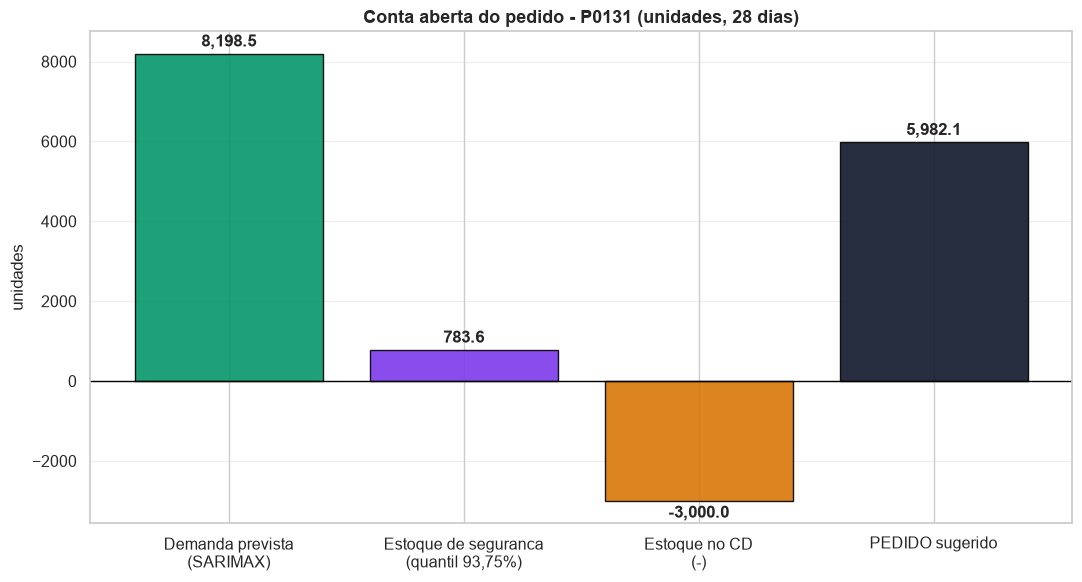

Figura salva em: C:\Users\flavi\Documents\GitHub\Supply-Chain-Forecasting\reports\figures\fase6_conta_aberta_pedido_P0131.png


In [6]:
# Decomposicao visual da conta do pedido
fig, ax = plt.subplots(figsize=(11, 6))
rotulos = ["Demanda prevista\n(SARIMAX)", "Estoque de seguranca\n(quantil 93,75%)",
           "Estoque no CD\n(-)", "PEDIDO sugerido"]
valores = [demanda_prevista, ESTOQUE_SEGURANCA, -ESTOQUE_CD, pedido]
cores = ["#059669", "#7C3AED", "#D97706", "#0F172A"]
barras = ax.bar(rotulos, valores, color=cores, alpha=0.9, edgecolor="black")
for b, v in zip(barras, valores):
    ax.text(b.get_x() + b.get_width() / 2, v + (180 if v >= 0 else -420),
            "{:,.1f}".format(v), ha="center", fontsize=12, fontweight="bold")
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Conta aberta do pedido - {} (unidades, {} dias)".format(PRODUTO_FOCO, H),
             fontsize=13, fontweight="bold")
ax.set_ylabel("unidades")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
caminho_fig = os.path.join(PASTA_FIGURAS, "fase6_conta_aberta_pedido_{}.png".format(PRODUTO_FOCO))
plt.savefig(caminho_fig, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("Figura salva em: {}".format(caminho_fig))

### 6.6 — Caso do P0131 naquela quinta-feira
A média das últimas 4 semanas sugeria "pedido zero" (estoque de > 10.000 un acima da venda).
A política SARIMAX mostra que ainda era preciso repor, porque a demanda prevista de 28 dias
somada ao colchão de segurança excede o estoque disponível no CD.

In [7]:
print("RESUMO DA DECISAO — tela de quinta-feira (P0131)")
print("=" * 78)
print("  Processo atual (media 4 semanas): leitura de ~300 un/dia vs ~10.000 un em estoque -> pedido ~0")
print("  Politica proposta : pedido = {:.1f} (demanda prevista) + {:.1f} (seguranca) - {:.1f} (CD) = {:.1f} un".format(
    demanda_prevista, ESTOQUE_SEGURANCA, ESTOQUE_CD, pedido))
print("  Realizado do periodo: {:.0f} un".format(real_vendido))
print("  Resultado: o estoque do CD nao cobre a demanda esperada do horizonte; havia necessidade real de reposicao.")

RESUMO DA DECISAO — tela de quinta-feira (P0131)
  Processo atual (media 4 semanas): leitura de ~300 un/dia vs ~10.000 un em estoque -> pedido ~0
  Politica proposta : pedido = 8198.5 (demanda prevista) + 783.6 (seguranca) - 3000.0 (CD) = 5982.1 un
  Realizado do periodo: 8158 un
  Resultado: o estoque do CD nao cobre a demanda esperada do horizonte; havia necessidade real de reposicao.


## Conclusão da Fase 6
A política é uma **conta aberta**, não um número mágico. Cada parcela é rastreável e o comprador
pode questionar componentes específicos. Com o nível de serviço de 93,75% e o estoque de
segurança de ≈ 783,6 un, a sugestão de pedido para o período é de **≈ 5.982 un**, coerente com o
realizado de **8.158 un** e com o estoque já disponível no CD.